# OctreeCity tour: build a city, look at it, test it

This notebook builds the KAIST campus (Daejeon) from OpenStreetMap (or Gangnam,
Seoul, from cached data if the OSM servers are busy), then goes
through every part of the library. Each step ends with a **check** cell that
raises an error if something is wrong, so running the whole notebook is also a
test.

Needs internet once (the OSM download is cached in `data/`). No OpenFOAM needed.

In [1]:
import time, tempfile
from datetime import date
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import octreecity
from octreecity.easy import city_from_osm
from octreecity.render import render_top, render_section
from octreecity.columns import ColumnCity

DATA = Path("../data"); DATA.mkdir(exist_ok=True)
TMP = Path(tempfile.mkdtemp())          # temporary files, deleted at the end
plt.rcParams["figure.dpi"] = 90
print("octreecity loaded from", octreecity.__file__)

octreecity loaded from /Users/mahmoud/Projects/octreecity/src/octreecity/__init__.py


## 1. Build a city in one call

`city_from_osm(lat, lon, size_m, cell)` downloads buildings, land cover,
trees, water and roads, projects them to UTM metres and builds the voxels.

In [2]:
PLACES = {"KAIST campus, Daejeon": (36.3700, 127.3625, 640, DATA / "osm_kaist_640.json"),
          "Gangnam station, Seoul": (37.4979, 127.0276, 800, DATA / "osm_gangnam.json")}
t = time.perf_counter()
for PLACE, (LAT, LON, SIZE, cache) in PLACES.items():
    try:
        city = city_from_osm(LAT, LON, size_m=SIZE, cell=1.0, cache=cache)
        break
    except RuntimeError as err:          # public Overpass servers are sometimes overloaded
        print(f"{PLACE}: download failed, trying the next place with cached data")
else:
    raise RuntimeError("no OSM data: check the internet connection and run again later")
print(f"{PLACE}: built in {time.perf_counter() - t:.1f} s")
print("columns:", city.shape, "| cell:", city.voxel_size, "m | CRS:", city.crs)
print(f"runs: {city.n_runs:,} | in memory: {city.nbytes / 1e6:.1f} MB | "
      f"a dense grid would be {np.prod(city.shape) / 1e6:.0f} MB")

KAIST campus, Daejeon: download failed, trying the next place with cached data


Gangnam station, Seoul: built in 36.2 s
columns: (800, 800, 171) | cell: 1.0 m | CRS: EPSG:32652
runs: 1,471,196 | in memory: 9.5 MB | a dense grid would be 109 MB


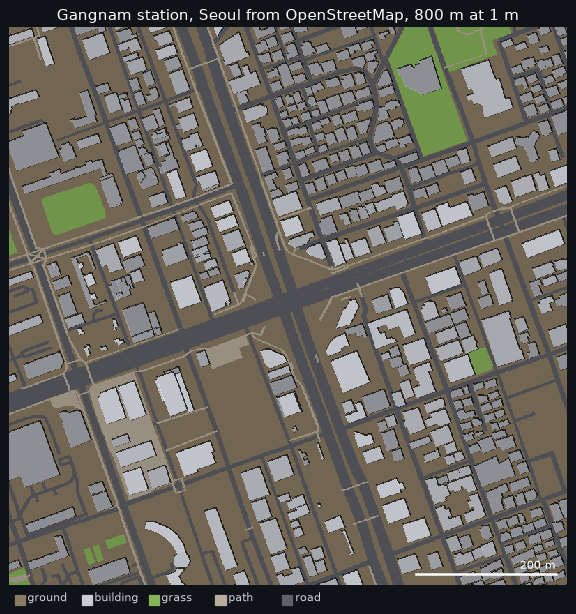

In [3]:
fig, ax = plt.subplots(figsize=(8, 8.4), facecolor="#0f1318")
render_top(city, ax)
ax.set_title(f"{PLACE} from OpenStreetMap, {SIZE} m at 1 m", color="w");

### Check: the city has buildings, trees, roads and air, and every column reaches the top

In [4]:
labels = set(np.unique(city.label).tolist())
names = {0: "air", 1: "ground", 2: "building", 3: "tree", 4: "water", 5: "grass", 6: "path", 7: "road"}
print("labels present:", [names.get(l, l) for l in sorted(labels)])
assert {0, 2, 7} <= labels, "expected air, buildings and roads"
assert city.offsets[-1] == city.n_runs
last = city.offsets[1:] - 1
assert (city.top[last] == city.shape[2]).all(), "every column must end at the box top"
print("OK")

labels present: ['air', 'ground', 'building', 'grass', 'path', 'road']
OK


## 2. Columns: exact, compact storage

Every (x, y) column is a list of runs: *ground up to 1, building up to 34, air
up to 60*. Converting to a dense grid and back must give the same runs.

In [5]:
sub = ColumnCity.from_dense(city.to_dense(0, 128))
dense = sub.to_dense()
back = ColumnCity.from_dense(dense)
assert (back.top == sub.top).all() and (back.label == sub.label).all()

rng = np.random.default_rng(0)
p = rng.integers(0, [128, city.shape[1], city.shape[2]], (20000, 3)).T
assert (sub.label_at(*p) == dense[p[0], p[1], p[2]]).all()

city.save(TMP / "kaist.npz")
again = ColumnCity.load(TMP / "kaist.npz")
assert (again.to_dense(0, 64) == city.to_dense(0, 64)).all() and again.crs == city.crs
print(f"OK: dense round trip, 20,000 point lookups, save/load "
      f"({(TMP / 'kaist.npz').stat().st_size / 1e6:.2f} MB on disk)")

OK: dense round trip, 20,000 point lookups, save/load (0.13 MB on disk)


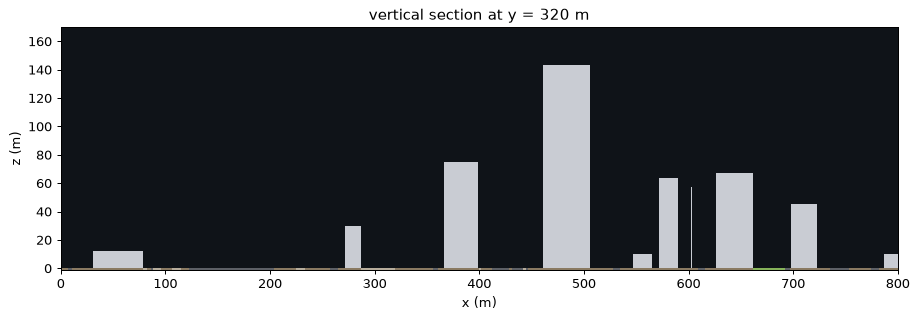

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.5))
render_section(city, ax, y=320)
ax.set_title("vertical section at y = 320 m")
ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)");

## 3. Octree: adaptive cells on demand

`to_octree(max_level)` merges equal neighbours into cubes of 1, 2, 4 ... 2^max_level cells.

In [7]:
t = time.perf_counter()
tree = city.to_octree(5)                      # 1 m to 32 m cells
print(f"{tree.n_leaves:,} cells (vs {np.prod(tree.shape):,} voxels) in {time.perf_counter() - t:.1f} s")
print("cells per size (m):", dict(zip([2**k for k in range(6)], tree.level_histogram().tolist())))
tree.check()                                   # aligned, inside the box, no gaps or overlaps
d = tree.to_dense()
assert (d[..., :city.shape[2]] == city.to_dense()).all() and (d[..., city.shape[2]:] == 0).all()
print("OK: octree tiles the box exactly and matches the columns")

3,680,409 cells (vs 122,880,000 voxels) in 1.1 s
cells per size (m): {1: 3030760, 2: 513875, 4: 111458, 8: 18063, 16: 3681, 32: 2572}


OK: octree tiles the box exactly and matches the columns


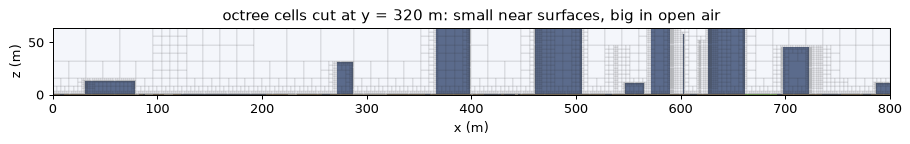

In [8]:
from octreecity.export import plot_slice
fig, ax = plt.subplots(figsize=(12, 3.5))
plot_slice(tree, ax, axis="y", index=320)
ax.set_ylim(0, 64)
ax.set_title("octree cells cut at y = 320 m: small near surfaces, big in open air");

## 4. Choose the min and max cell size (metres)

`build_city` takes a height raster and the cell sizes you want.

In [9]:
from octreecity import build_city
from octreecity.analysis import ground_level, surface_height

heights = surface_height(city) - ground_level(city)       # object height per 1 m pixel
rows = []
for mn, mx in [(1, 32), (2, 32), (4, 64), (0.5, 16)]:
    t = time.perf_counter()
    tr = build_city(heights, pixel_size=1.0, min_cell=mn, max_cell=mx)
    s = tr.sizes() * tr.voxel_size
    assert s.min() >= mn and s.max() <= mx
    rows.append((mn, mx, tr.n_leaves, 1e3 * (time.perf_counter() - t)))
for r in rows:
    print(f"min {r[0]:>4} m  max {r[1]:>3} m  -> {r[2]:>9,} cells  {r[3]:6.0f} ms")
print("OK: every cell respects its limits")

min    1 m  max  32 m  -> 3,680,409 cells     335 ms
min    2 m  max  32 m  ->   833,369 cells     127 ms
min    4 m  max  64 m  ->   202,100 cells      22 ms
min  0.5 m  max  16 m  -> 9,618,214 cells     890 ms
OK: every cell respects its limits


## 5. Analysis: sky view factor and sun hours at street level

112,225 points | SVF 4.9 s | sun hours 1.8 s


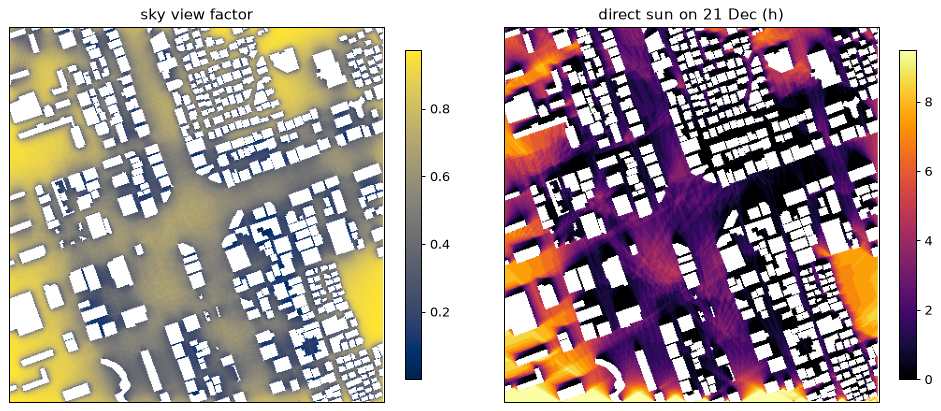

In [10]:
from octreecity.analysis import street_points, sky_view_factor, sun_hours

pts, (ii, jj) = street_points(city, every=2)
t = time.perf_counter(); svf = sky_view_factor(city, pts); t_svf = time.perf_counter() - t
t = time.perf_counter()
sun = sun_hours(city, pts, LAT, LON, date(2026, 12, 21), tz_hours=9, step_min=30)
t_sun = time.perf_counter() - t
print(f"{len(pts):,} points | SVF {t_svf:.1f} s | sun hours {t_sun:.1f} s")
assert 0 <= svf.min() and svf.max() <= 1 and 0 <= sun.min() and sun.max() <= 10.5

def as_map(v):
    g = np.full((city.shape[0] // 2 + 1, city.shape[1] // 2 + 1), np.nan)
    g[ii // 2, jj // 2] = v
    return g.T

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, v, cm, title in ((axes[0], svf, "cividis", "sky view factor"),
                         (axes[1], sun, "inferno", "direct sun on 21 Dec (h)")):
    im = ax.imshow(as_map(v), origin="lower", cmap=cm); ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([]); fig.colorbar(im, ax=ax, fraction=0.04)

### Check against known answers: an open field has SVF 1, a 30 m wall casts a 30 m shadow at 45°

In [11]:
from octreecity.analysis import shadow
from octreecity import BUILDING

flat = ColumnCity.from_heightfield(np.ones((64, 64)), np.ones((64, 64)), BUILDING, 8)
assert abs(sky_view_factor(flat, np.array([[32.0, 32.0, 2.5]]))[0] - 1) < 1e-9

g = np.ones((200, 200)); s = g.copy(); s[:, 100:110] += 30
wall = ColumnCity.from_heightfield(g, s, BUILDING, 40)
y = np.arange(60, 100) + 0.5
dark = shadow(wall, np.stack([np.full_like(y, 50.0), y, np.ones_like(y)], 1), sun_az=0, sun_alt=45)
print("shadow starts at y =", y[dark].min(), "(wall at y = 100, expected about 70)")
assert 68 <= y[dark].min() <= 72
print("OK")

shadow starts at y = 70.5 (wall at y = 100, expected about 70)
OK


## 6. adapt(): follow any field

Here the field is synthetic: a shear layer 6 m above the roofs. Cells split
where neighbours differ by more than the tolerance and merge where it is calm.
Swap `field` for wind, noise, temperature or an ML prediction.

round 1: 455,947 cells


round 2: 533,052 cells


round 3: 697,853 cells
OK: geometry unchanged, cells refined around the shear layer


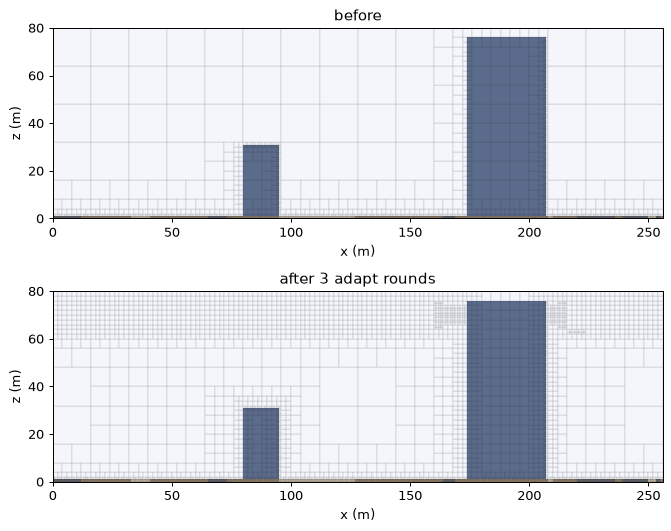

In [12]:
from octreecity.adapt import adapt, sample

part = ColumnCity.from_dense(city.to_dense(192, 448)[:, 192:448])     # 256 m block
t0 = part.to_octree(4)
roof = np.percentile(surface_height(part) - part.origin[2], 90)
field = lambda x, y, z: np.tanh((z - part.origin[2] - roof - 6) / 3.0)
t1, v = t0, sample(t0, field)
for k in range(3):
    t1, v = adapt(t1, v, refine_tol=0.25, min_level=0)
    v = sample(t1, field)
    print(f"round {k + 1}: {t1.n_leaves:,} cells")
t1.check()
assert (t1.to_dense() == t0.to_dense()).all(), "geometry must not change"
print("OK: geometry unchanged, cells refined around the shear layer")

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for ax, tr, name in ((axes[0], t0, "before"), (axes[1], t1, "after 3 adapt rounds")):
    plot_slice(tr, ax, axis="y", index=128); ax.set_ylim(0, 80); ax.set_title(name)
fig.tight_layout()

## 7. Exports: OBJ mesh, ML tensors, OpenFOAM mesh

In [13]:
from octreecity.exports import write_obj, tensors_2d, tensors_3d, surface_quads

n = write_obj(part, TMP / "block.obj", labels=[2])
print(f"OBJ: {n:,} faces, {(TMP / 'block.obj').stat().st_size / 1e6:.1f} MB")
q, _ = surface_quads(part, labels=[2])
tri = np.concatenate([q[:, [0, 1, 2]], q[:, [0, 2, 3]]])
vol = np.einsum("ij,ij->i", tri[:, 0], np.cross(tri[:, 1], tri[:, 2])).sum() / 6
assert np.isclose(vol, (part.to_dense() == 2).sum() * part.voxel_size**3), "mesh must be closed"

x, names = tensors_2d(city, factor=2)
v3 = tensors_3d(part, labels=[2, 3], factor=4)
print("2D tensor", x.shape, names[:4], "| 3D tensor", v3.shape)
print("OK: closed mesh with the right volume, tensors ready")

OBJ: 3,460 faces, 0.4 MB


2D tensor (12, 400, 400) ['height', 'ground', 'frac_1', 'top_1'] | 3D tensor (2, 64, 64, 42)
OK: closed mesh with the right volume, tensors ready


In [14]:
from octreecity.foam import build_polymesh, check_polymesh, write_polymesh

small = ColumnCity.from_dense(city.to_dense(256, 384)[:, 256:384])     # 128 m block
ft = small.to_octree(4)
ft.limit_size_near([1, 2, 3], distance=4, max_level=0)
ft.balance(26)
t = time.perf_counter()
mesh = build_polymesh(ft)
rep = check_polymesh(mesh)
write_polymesh(mesh, TMP / "case")
print(f"OpenFOAM mesh: {rep['cells']:,} cells, {rep['faces']:,} faces in {time.perf_counter() - t:.1f} s")
print("patches:", [(p[0], p[2]) for p in mesh["patches"]])
assert rep["max_open"] < 1e-9 and rep["min_volume"] > 0, rep
print("OK: every cell closed, all volumes positive (files in", TMP / "case", ")")

OpenFOAM mesh: 164,813 cells, 531,563 faces in 0.9 s
patches: [('xmin', 1691), ('xmax', 2384), ('ymin', 1635), ('ymax', 650), ('zmax', 64), ('ground', 9689), ('building', 16720), ('pavement', 1883), ('road', 3676)]
OK: every cell closed, all volumes positive (files in /var/folders/35/8k4pd_fn1j7g1p0qjbt7w_fc0000gn/T/tmp5mseut9i/case )


## 8. Run the full test suite

In [15]:
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "../tests"], capture_output=True, text=True)
print(r.stdout[-600:])
assert r.returncode == 0, r.stderr[-2000:]

....................................................                     [100%]
52 passed in 1.88s



In [16]:
import shutil
shutil.rmtree(TMP)
print("temporary files removed; every check passed")

temporary files removed; every check passed
